# Дополнительный ноутбук 1. Глобальная температура и сравнение с Беларусью

**Файл:** `GlobalTemperatures.csv` — глобальные средние температуры суши (с 1750 г.) и суши+океана (с 1850 г.).

**Задача:** посмотреть на долгосрочный глобальный тренд, оценить скорость потепления и сравнить её с трендом по Беларуси из основного ноутбука.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True

DATA_DIR = '../data'


In [16]:
g = pd.read_csv(f'{DATA_DIR}/GlobalTemperatures.csv', parse_dates=['dt']).set_index('dt').sort_index()
print(f'Период: {g.index.min().date()} — {g.index.max().date()}')
print(f'Пропуски LandAverageTemperature: {g["LandAverageTemperature"].isna().sum()}')
print(f'Пропуски LandAndOceanAverageTemperature: {g["LandAndOceanAverageTemperature"].isna().sum()}')
print('\nКолонки:', list(g.columns))
g.head(3)

Период: 1750-01-01 — 2015-12-01
Пропуски LandAverageTemperature: 12
Пропуски LandAndOceanAverageTemperature: 1200

Колонки: ['LandAverageTemperature', 'LandAverageTemperatureUncertainty', 'LandMaxTemperature', 'LandMaxTemperatureUncertainty', 'LandMinTemperature', 'LandMinTemperatureUncertainty', 'LandAndOceanAverageTemperature', 'LandAndOceanAverageTemperatureUncertainty']


,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
dt,,,,,,,,
1750-01-01,3.034,3.574,NaN,NaN,NaN,NaN,NaN,NaN
1750-02-01,3.083,3.702,NaN,NaN,NaN,NaN,NaN,NaN
1750-03-01,5.626,3.076,NaN,NaN,NaN,NaN,NaN,NaN


## Долгосрочный ряд

Средняя температура суши доступна с 1750 года, однако ранние измерения имеют большую неопределённость (ртутные термометры, мало станций). Совмещённый ряд «суша + океан» начинается только с 1850 года.

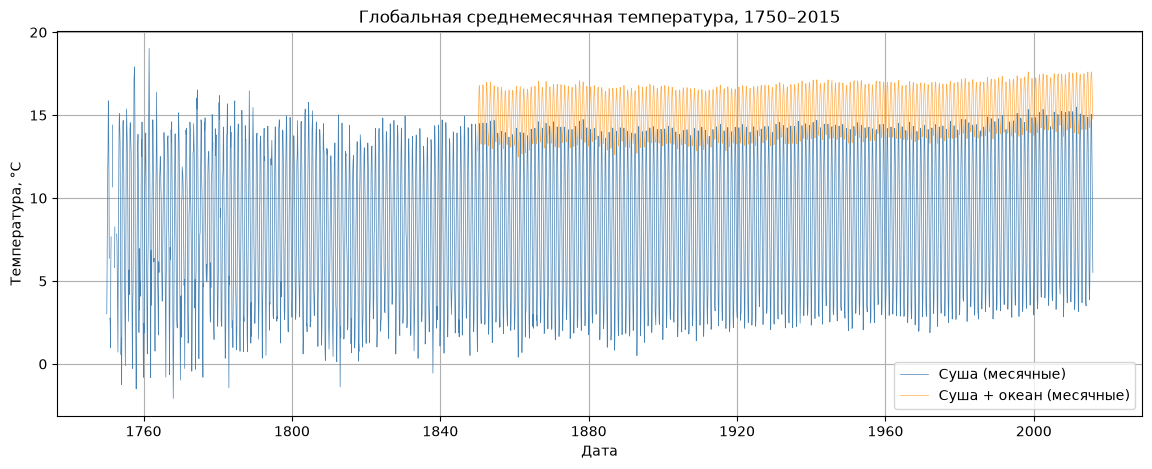

In [17]:
fig, ax = plt.subplots()
ax.plot(g.index, g['LandAverageTemperature'], lw=0.5, color='steelblue', label='Суша (месячные)')
ax.plot(g.index, g['LandAndOceanAverageTemperature'], lw=0.5, color='darkorange', alpha=0.7, label='Суша + океан (месячные)')
ax.set_title('Глобальная среднемесячная температура, 1750–2015')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

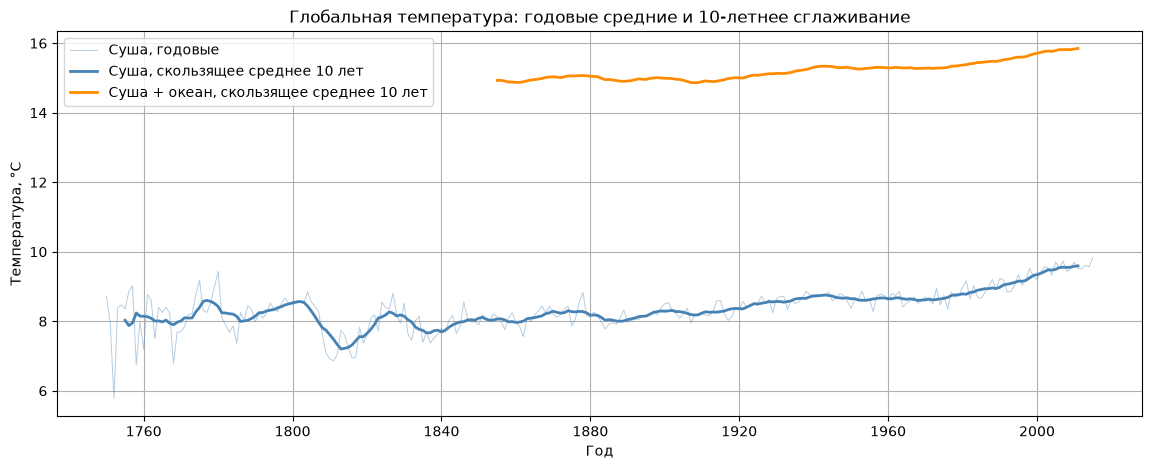

In [18]:
# Годовые средние + сглаживание 10-летним окном
g_land_ann = g['LandAverageTemperature'].resample('YS').mean()
g_ocean_ann = g['LandAndOceanAverageTemperature'].resample('YS').mean()

fig, ax = plt.subplots()
ax.plot(g_land_ann.index, g_land_ann, lw=0.7, color='steelblue', alpha=0.4, label='Суша, годовые')
ax.plot(g_land_ann.index, g_land_ann.rolling(10, center=True).mean(), lw=2, color='steelblue', label='Суша, скользящее среднее 10 лет')
ax.plot(g_ocean_ann.index, g_ocean_ann.rolling(10, center=True).mean(), lw=2, color='darkorange', label='Суша + океан, скользящее среднее 10 лет')
ax.set_title('Глобальная температура: годовые средние и 10-летнее сглаживание')
ax.set_xlabel('Год')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

## Оценка скорости потепления

Считаем линейный тренд годовых средних (°C за 100 лет) за разные периоды.

In [19]:
def trend_per_century(series):
    """Линейный тренд ряда в °C за 100 лет."""
    s = series.dropna()
    years = s.index.year.values.astype(float)
    return np.polyfit(years - years.mean(), s.values, 1)[0] * 100

trends_global = pd.DataFrame({
    'Период': ['1750–2015', '1900–2015', '1963–2015'],
    'Суша, °C/100 лет': [
        round(trend_per_century(g_land_ann), 2),
        round(trend_per_century(g_land_ann['1900':]), 2),
        round(trend_per_century(g_land_ann['1963':]), 2)],
    'Суша + океан, °C/100 лет': [
        np.nan,
        round(trend_per_century(g_ocean_ann['1900':]), 2),
        round(trend_per_century(g_ocean_ann['1963':]), 2)],
})
trends_global

,Период,"Суша, °C/100 лет","Суша + океан, °C/100 лет"
0,1750–2015,0.47,NaN
1,1900–2015,1.07,0.79
2,1963–2015,2.39,1.43


Потепление **ускоряется**: за последние 50 лет скорость роста температуры суши примерно вдвое выше, чем в среднем за XX–XXI вв. Суша нагревается быстрее, чем планета в целом, — океан обладает огромной тепловой инерцией и сглаживает тренд.

## Сравнение с Беларусью

Возьмём ряд по Беларуси из основного ноутбука и сравним тренды. Для корректного сравнения переведём оба ряда в **аномалии** — отклонения от среднего за общий базовый период 1951–1980 гг. (стандартная практика в климатологии).

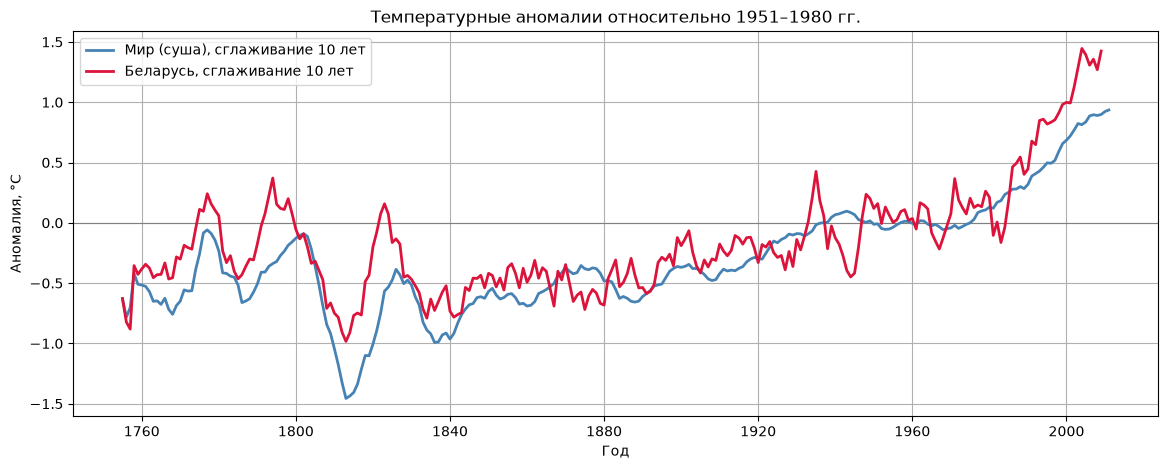

In [20]:
bel = pd.read_csv(f'{DATA_DIR}/GlobalLandTemperaturesByCountry.csv')
bel = (bel.loc[bel['Country'] == 'Belarus', ['dt', 'AverageTemperature']]
         .assign(dt=lambda x: pd.to_datetime(x['dt']))
         .set_index('dt').sort_index())
bel_ann = bel['AverageTemperature'].resample('YS').mean()

# Аномалии относительно базового периода 1951–1980
base = slice('1951', '1980')
g_land_anom = g_land_ann - g_land_ann.loc[base].mean()
bel_anom = bel_ann - bel_ann.loc[base].mean()

fig, ax = plt.subplots()
ax.axhline(0, color='grey', lw=0.8)
ax.plot(g_land_anom.index, g_land_anom.rolling(10, center=True).mean(), lw=2, color='steelblue',
        label='Мир (суша), сглаживание 10 лет')
ax.plot(bel_anom.index, bel_anom.rolling(10, center=True).mean(), lw=2, color='crimson',
        label='Беларусь, сглаживание 10 лет')
ax.set_title('Температурные аномалии относительно 1951–1980 гг.')
ax.set_xlabel('Год')
ax.set_ylabel('Аномалия, °C')
ax.legend()
plt.show()

In [21]:
compare = pd.DataFrame({
    'Период': ['1900–2013', '1963–2013'],
    'Мир (суша), °C/100 лет': [
        round(trend_per_century(g_land_ann['1900':'2013']), 2),
        round(trend_per_century(g_land_ann['1963':'2013']), 2)],
    'Беларусь, °C/100 лет': [
        round(trend_per_century(bel_ann['1900':]), 2),
        round(trend_per_century(bel_ann['1963':]), 2)],
})
compare

,Период,"Мир (суша), °C/100 лет","Беларусь, °C/100 лет"
0,1900–2013,1.04,1.38
1,1963–2013,2.37,3.92


## Выводы

1. Глобальная температура суши растёт: тренд XX–XXI вв. — около **+1.1 °C за 100 лет**, а за последние 50 лет потепление ускорилось примерно до **+2.4 °C за 100 лет**.
2. Беларусь теплеет **быстрее планеты в среднем** (~+1.4 °C/100 лет за 1900–2013 и ~+3.9 °C/100 лет за последние 50 лет) — это типично для континентальных регионов умеренных широт, удалённых от океана.
3. Для сравнения климатических рядов удобно использовать аномалии относительно общего базового периода — так убирается разница в абсолютных температурах.